## All Simulations
Here I compare the theoretical and simulated seasonality metrics for a range of simulations.

In [1]:
import sys
import os
import inspect

from matplotlib import lines
from matplotlib.lines import Line2D

from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots

# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [2]:
from jobs.thesis_season.publish_figs.load import load_ds_all, width, day_seconds, exclude_params, params_all, label_temp, \
    unit_lambda, label_simulations, color_simulations
from jobs.thesis_season.publish_figs.energy_budget_empirical import get_approx_flux_atmos, get_empirical_params, \
    get_approx_mse_tend, get_heat_cap_lambda_eff, get_analytic_params
from jobs.thesis_season.publish_figs.xr_funcs import get_fit_complex_xr, apply_linear_zero_mean_xr, get_fourier_fit_xr

In [3]:
%%capture
exp_name = list(exclude_params.keys())
ds = {key: load_ds_all(key) for key in exp_name}
feedback_params = {key: get_empirical_params(ds[key], exclude_params=exclude_params[key]) for key in ds}
feedback_params_analytic = {key: get_analytic_params(ds[key]) for key in ds}
# for key in feedback_params:
#     feedback_params[key]['lambda_const'] = feedback_params[key]['lambda_const'] * 999999

### Amplitude and Lag expectations
Below I use the lag and amplitude from the Mckinnon paper. I compare this to a simple estimate from isolated surface with $C_{eff}=C_s$ and $\lambda_{eff} = 4\sigma \overline{T}_s^3$, where we take $\overline{T}_s=280$.

In [4]:
temp_naive = 280
lambda_eff_naive = 4*Stefan_Boltzmann*temp_naive**3
var = get_phase_amp(ds['base'].coef_sw_amp.sel(odp=1), ds['base'].omega, ds['base'].heat_cap_surf, lambda_eff_naive)
print(f"Naive lambda eff: {lambda_eff_naive:.1f} W/m2/K")
print(f"Naive lag estimate at {temp_naive}K: {var[0]/ds['base'].omega/day_seconds:.1f} days")
print(f"Naive amplitude estimate at {temp_naive}K: {var[1]:.1f}K")

gain_mckinnon = 131/1000                # Surface temp amp / insolation amp
lag_mckinnon = 22                       # in days
coef_insolation = ds['base'].coef_sw_amp/(1-ds['base'].albedo)/(1-ds['base'].sw_abs)
amp_mckinnon = gain_mckinnon * coef_insolation  # compute temp amp at the \metradiation here
amp_mckinnon = float(amp_mckinnon.sel(odp=1))
print(f"Mckinnon lag: {lag_mckinnon:.1f} days")
print(f"Mckinnon amplitude: {amp_mckinnon:.1f}K")

Naive lambda eff: 5.0 W/m2/K
Naive lag estimate at 280K: 9.5 days
Naive amplitude estimate at 280K: 20.1K
Mckinnon lag: 22.0 days
Mckinnon amplitude: 23.5K


In [5]:
# Compute theoretical lambda_eff etc using simple theory
approx_errors = {}
arg_names = list(inspect.signature(get_heat_cap_lambda_eff).parameters.keys())
for key in ds:
    arg_use = {key2: feedback_params[key][key2].copy() for key2 in arg_names if key2 in feedback_params[key]}
    arg_use['heat_cap_surf'] = ds[key].heat_cap_surf
    arg_use['pressure_heat_cap_atmos_calc'] = ds[key].p_integ_calc.mean(dim='time')
    arg_use['sw_abs'] = ds[key].sw_abs
    arg_use['albedo'] = ds[key].albedo
    ds[key]['lambda_eff_theory'], ds[key]['heat_cap_eff_theory'], approx_errors[key] = get_heat_cap_lambda_eff(**arg_use, infinite_lambda_approx=True)
    ds[key]['coef_phase_theory'], ds[key]['coef_amp_theory'] = get_phase_amp(ds[key].coef_sw_amp, ds[key].omega,
                                                               ds[key]['heat_cap_eff_theory'], ds[key]['lambda_eff_theory'])
    for key2 in ['lambda_eff', 'heat_cap_eff', 'coef_phase', 'coef_amp']:
        for key3 in ['', '_theory']:
            ds[key][f'{key2}{key3}_regress'] = np.polyfit(ds[key].temp_surf.mean(dim='time'), ds[key][f'{key2}{key3}'], deg=1)[0]

### Effect of each parameter
We see that $\Lambda$ acts to increase the effective feedback parameter. This is because if it is zero, then $b'$ is quite large and positive, but if it is positive, $b'$ goes back closer to zero, as expected with $\lambda = \infty$.

In [6]:
def get_B_naive(ds):
    # This estimates assumes \Delta T_olr = \Delta T_a, so does not take account of lapse rate effect
    emiss_factor = 1 - np.exp(-ds.odp_surf)
    temp_olr = (ds.olr / (Stefan_Boltzmann * emiss_factor)) ** 0.25
    return 4 * Stefan_Boltzmann * emiss_factor * temp_olr.mean(dim='time') ** 3

In [7]:
param_ref = {'sw_abs': 0, 'lambda_const': 999999999, 'coef_amp_col': 1, 'mu': 0, 'B': 2.8, 'lambda_a': 0, 'coef_phase_col': 0, 'coef_phase_olr': 0,
             'coef_phase_a': 0, 'lambda_adv': 0, 'B': 2.8}      # For B, use value from Barsugli and Battisti
odp_use = 1

def get_phase_info2(param_set_ref, params, params_ref, pressure_heat_cap_atmos_calc,
                   heat_cap_surf, sw_abs, coef_sw_amp,
                   albedo=ds['base'].albedo, omega=ds['base'].omega):
    # Function to compute heat_cap, lambda, phase and amplitude with default parameters except one which is set to a ref value
    arg_names = list(inspect.signature(get_heat_cap_lambda_eff).parameters.keys())
    arg_names = [key for key in arg_names if key != 'sw_abs']
    arg_use = {key: params[key] for key in arg_names if key in params_ref}
    arg_use['heat_cap_surf'] = heat_cap_surf
    arg_use['pressure_heat_cap_atmos_calc'] = pressure_heat_cap_atmos_calc
    arg_use['sw_abs'] = sw_abs
    arg_use['albedo'] = albedo
    if param_set_ref is not None:
        arg_use[param_set_ref] = arg_use[param_set_ref]*0 + params_ref[param_set_ref]
    lambda_eff, heat_cap_eff, error = get_heat_cap_lambda_eff(**arg_use)
    phase, amp = get_phase_amp(coef_sw_amp, omega, heat_cap_eff, lambda_eff)
    return heat_cap_eff / heat_cap_surf, lambda_eff, phase / omega / day_seconds, amp


phase_info_full_theory = {key: {} for key in ds}
for key in ds:
    phase_info_full_theory[key]['heat_cap'], phase_info_full_theory[key]['lambda'], \
        phase_info_full_theory[key]['lag'], phase_info_full_theory[key]['amp'] = \
        get_phase_info2(None, feedback_params[key], param_ref, ds[key].p_integ_calc.mean(dim='time'),
                        ds[key].heat_cap_surf, ds[key].sw_abs, ds[key].coef_sw_amp)


phase_info_regress_full_theory = {key: {key2: 0 for key2 in phase_info_full_theory[key]} for key in phase_info_full_theory}
for key in phase_info_regress_full_theory:
    for key2 in phase_info_regress_full_theory[key]:
        phase_info_regress_full_theory[key][key2] = np.polyfit(ds[key].temp_surf.mean(dim='time'), phase_info_full_theory[key][key2], deg=1)[0]

def get_error(var, var_approx):
    return (var-var_approx)/np.abs(var) * 100

phase_info_error = {key: {key2: {} for key2 in param_ref} for key in ds}
phase_info_regress_error = {key: {key2: {} for key2 in param_ref} for key in ds}
for key in ds:
    for key2 in param_ref:
        var_param = {}
        var_param['heat_cap'], var_param['lambda'], var_param['lag'], var_param['amp'] = \
        get_phase_info2(key2, feedback_params[key], param_ref, ds[key].p_integ_calc.mean(dim='time'),
                        ds[key].heat_cap_surf, ds[key].sw_abs, ds[key].coef_sw_amp)
        for key3 in var_param:
            phase_info_error[key][key2][key3] = get_error(phase_info_full_theory[key][key3], var_param[key3])
            var_regress = np.polyfit(ds[key].temp_surf.mean(dim='time'), var_param[key3], deg=1)[0]
            phase_info_regress_error[key][key2][key3] = get_error(phase_info_regress_full_theory[key][key3], var_regress)


feedback_params_regress = {key: {} for key in feedback_params}
for key in feedback_params:
    for key2 in feedback_params[key]:
        feedback_params_regress[key][key2]= np.polyfit(ds[key].temp_surf.mean(dim='time'), feedback_params[key][key2], deg=1)[0]

# phase_info_regress = {key: {key2: {} for key2 in phase_info_full_theory[key]} for key in phase_info_full_theory}
# for key in phase_info_regress:
#     for key2 in phase_info_regress[key]:
#         phase_info_regress[key][key2]['full'] = np.polyfit(ds[key].temp_surf.mean(dim='time'), phase_info_full_theory[key][key2], deg=1)[0]
        # for key3 in param_ref:
        #     phase_info_regress[key][key2][key3] = np.polyfit(ds[key].temp_surf.mean(dim='time'), phase_info_full_theory[key][key2], deg=1)[0]


In [8]:
for key in feedback_params_regress:
    print(key, feedback_params_regress[key]['coef_amp_col'])

base 0.026619859502609977
advect 0.016572340551508406
dry 0.002498768156062248
fix_rh 0.014611948452442517
ocean 0.030990739684870452
sw_abs_high 0.024570522661090746
sw_abs_low 0.02632293152946011
wind_high 0.02771213473985912
wind_low 0.01974958654962562


In [9]:
style_param = {'lambda_const': ['k', r'$\lambda$'],
               'lambda_const_lh': ['C0', 'LH'],
               'lambda_const_sh': ['C2', 'SH'],
               'lambda_const_lw': ['C1', 'LW'],
               'lambda_a': ['k', r'$\Lambda$'],
               'coef_phase_a': ['k', r'$\phi_{\Lambda}$'],
               'lambda_a_lh': ['C0', r'$\Lambda_{\text{LH}}$'],
               'coef_phase_a_lh': ['C0', r'$\phi_{\Lambda_{\text{LH}}$'],
               'B': ['C1', r'$B$'],
               'coef_phase_olr': ['C1', r'$\phi_B$'],
               'lambda_adv': ['C3', r"$B_{\text{adv}}$"],
               'base': '-',
               'advect': '--',
               'analytic': ':',
               'mu': ['C0', r'$\mu$'],
               'coef_amp_col': ['C2', r'$\beta$'],
               'coef_phase_col': ['C2', r'$\phi_{\beta}$'],
               'sw_abs': ['C0', '$f$']}

In [10]:
def plot_eff_error(
    phase_info_error,
    phase_info_regress_error=None,
    *,
    odp_ref=1,
    regress=False,
):
    """
    regress=False: select errors at odp=odp_ref.
    regress=True:  use scalar errors from phase_info_regress_error.

    Simulation and parameter order follow phase_info_error.
    Missing entries remain NaN.
    """
    if regress and phase_info_regress_error is None:
        raise ValueError(
            "phase_info_regress_error is required when regress=True."
        )

    keys_sim = list(phase_info_error)
    keys_param = list(dict.fromkeys(
        param
        for simulation in phase_info_error.values()
        for param in simulation
    ))
    keys_plot = ["heat_cap", "lambda"]
    titles = [
        r"Effective heat capacity, $C_{\mathrm{eff}}$",
        r"Effective damping, $\lambda_{\mathrm{eff}}$",
    ]

    errors = phase_info_regress_error if regress else phase_info_error

    def get_error(sim, param, name):
        # Retain the original eligibility check against phase_info_error.
        original = phase_info_error[sim].get(param, {})
        if name not in original:
            return np.nan

        value = errors.get(sim, {}).get(param, {}).get(name, np.nan)
        return value if regress else value.sel(odp=odp_ref).item()

    error_plot = {
        name: np.array([
            [get_error(sim, param, name) for param in keys_param]
            for sim in keys_sim
        ], dtype=float)
        for name in keys_plot
    }

    # Shared symmetric colour scale.
    values = np.concatenate([data.ravel() for data in error_plot.values()])
    values = values[np.isfinite(values)]
    vmax = np.max(np.abs(values)) if values.size else 1
    vmax = vmax if vmax > 0 else 1
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("0.9")

    labels_param = [
        style_param[param][1] if param in style_param else param
        for param in keys_param
    ]
    labels_sim = [label_simulations.get(sim, sim) for sim in keys_sim]

    fig, ax = plt.subplots(2, 1, sharex=True, sharey=True)
    fig_resize(fig, width["two_col"])
    fig.set_figheight(max(4.5, 1.8 + 0.75 * len(keys_sim)))

    for axis, name, title in zip(ax, keys_plot, titles):
        data = error_plot[name]
        im = axis.imshow(
            data,
            cmap=cmap,
            norm=norm,
            aspect="auto",
            interpolation="nearest",
        )

        axis.set_title(title)
        axis.set_yticks(np.arange(len(keys_sim)))
        axis.set_yticklabels(labels_sim)
        axis.set_xticks(np.arange(len(keys_param)))

        # Cell boundaries.
        axis.set_xticks(np.arange(len(keys_param) + 1) - 0.5, minor=True)
        axis.set_yticks(np.arange(len(keys_sim) + 1) - 0.5, minor=True)
        axis.grid(False)
        axis.grid(which="minor", color="white", linewidth=1)
        axis.tick_params(which="minor", bottom=False, left=False)

        for (row, col), value in np.ndenumerate(data):
            if not np.isfinite(value):
                continue

            # Avoid displaying negative zero.
            value = 0 if abs(value) < 0.5 else value
            axis.text(
                col, row, f"{value:.0f}",
                ha="center",
                va="center",
                color="white" if abs(value) > 0.65 * vmax else "black",
            )

    ax[1].set_xticklabels(labels_param)

    fig.subplots_adjust(
        left=0.10, right=0.88, bottom=0.24, top=0.87, hspace=0.15,
    )

    cax = fig.add_axes([0.90, 0.25, 0.015, 0.58])
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Relative difference [%]")

    label_subplots(fig, ax.flatten(), pos_y=12, box_alpha=0)
    return fig, ax

In [14]:
ds['sw_abs_low']

<xarray.Dataset> Size: 1MB
Dimensions:                      (pfull: 25, odp: 8, time: 360)
Coordinates:
    lon                          float64 8B 0.0
    lat                          float64 8B 43.25
  * pfull                        (pfull) float64 200B 4.329 15.55 ... 994.9
  * odp                          (odp) float64 64B 0.6 0.8 1.0 ... 2.5 3.0 3.5
  * time                         (time) int64 3kB 0 1 2 3 4 ... 356 357 358 359
Data variables: (12/54)
    temp                         (time, odp, pfull) float32 288kB 215.1 ... 2...
    p_surf                       (time, odp) float32 12kB 1e+05 1e+05 ... 1e+05
    sphum                        (time, odp, pfull) float32 288kB 2e-06 ... 0...
    olr                          (time, odp) float32 12kB 156.5 148.8 ... 159.2
    swdn_toa                     (time, odp) float32 12kB 134.0 134.0 ... 134.0
    swdn_sfc                     (time, odp) float32 12kB 75.69 92.44 ... 92.44
    ...                           ...
    heat_cap_eff_regress         float64 8B 5.534e+05
    heat_cap_eff_theory_regress  float64 8B 4.329e+05
    coef_phase_regress           float64 8B 0.004211
    coef_phase_theory_regress    float64 8B 0.005156
    coef_amp_regress             float64 8B -0.4877
    coef_amp_theory_regress      float64 8B -0.513
Attributes: (12/14)
    filename:        atmos_daily.nc
    title:           FMS Model results
    grid_type:       regular
    grid_tile:       N/A
    evap_prefactor:  1
    albedo:          0.31
    ...              ...
    w_atm:           10
    p_ref:           100000.0
    heat_cap_surf:   4128868.526280635
    odp:             0.6
    atm_abs:         0.2
    omega:           2.0200570046230665e-07

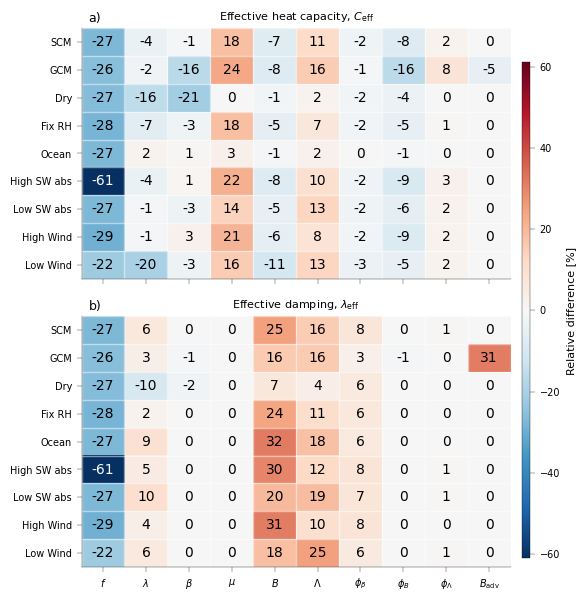

In [11]:
show_regress=False
fig, ax = plot_eff_error(
    phase_info_error,
    phase_info_regress_error,
    odp_ref=odp_use,
    regress=show_regress,
)
plt.show()
# savefig(fig, file_name='z_param_effect_regress' if show_regress else 'z_param_effect')

In [ ]:
def plot_eff_response(
    ds,
    exp_name,
    *,
    odp_ref=1,
    regress=False,
):
    """
    regress=False: use the original variables, selecting odp=odp_ref.
    regress=True:  use variables with '_regress' appended, without odp selection.
    """
    suffix = "_regress" if regress else ""

    def get_var(d, name, method):
        value = d[f"{name}{method}{suffix}"]
        return value if regress else value.sel(odp=odp_ref)

    fig, ax = plt.subplots(1, 2)
    fig_resize(fig, width["two_col"] * 1.5)

    for i, key in enumerate(exp_name):
        color = color_simulations[key]
        d = ds[key]

        # Order: simulation, theory
        methods = ["", "_theory"]

        x = [
            [
                get_var(d, "heat_cap_eff", method) / d.heat_cap_surf
                for method in methods
            ],
            [
                get_var(d, "coef_phase", method) / day_seconds / d.omega
                for method in methods
            ],
        ]
        y = [
            [get_var(d, "lambda_eff", method) for method in methods],
            [get_var(d, "coef_amp", method) for method in methods],
        ]

        if regress:
            # Convert panel 0 to % change per K.
            # Use base simulated value as normalisation factor.
            # Same normalisation for all epxeriments, so just results in shift in magnitude
            # no relative changes between experiments.
            x[0] = [
                100 * get_var(d, "heat_cap_eff", method)
                /ds['base'][f"heat_cap_eff"].sel(odp=odp_ref)
                #/ d[f"heat_cap_eff{method}"].sel(odp=odp_ref)
                for method in methods
            ]
            y[0] = [
                100 * get_var(d, "lambda_eff", method)
                /ds['base'][f"lambda_eff"].sel(odp=odp_ref)
                #/ d[f"lambda_eff{method}"].sel(odp=odp_ref)
                for method in methods
            ]

        for panel, axis in enumerate(ax):
            axis.plot(
                x[panel], y[panel],
                color=color, lw=1.4, alpha=0.55, zorder=2,
            )

            # Simulation: filled circle.
            axis.scatter(
                x[panel][0], y[panel][0],
                color=color, marker="o", s=48,
                edgecolors="white", linewidths=0.6, zorder=3,
                label=label_simulations[key] if panel == 0 else None,
            )

            # Theory: open circle.
            axis.scatter(
                x[panel][1], y[panel][1],
                marker="o", s=55,
                facecolors="none", edgecolors=color,
                linewidths=1.6, zorder=4,
            )

    for axis in ax:
        axis.set_axisbelow(True)
        axis.grid(alpha=0.15, linewidth=0.6)
        axis.spines[["top", "right"]].set_visible(False)
        axis.tick_params(direction="out")

    ax[0].legend(ncol=2, frameon=False, loc='upper left')

    method_handles = [
        Line2D(
            [], [], color="0.25", marker="o", linestyle="none",
            markersize=6, label="Simulated",
        ),
        Line2D(
            [], [], color="0.25", marker="o", linestyle="none",
            markerfacecolor="none", markersize=7,
            markeredgewidth=1.6, label="Theory",
        ),
    ]
    ax[1].legend(handles=method_handles, frameon=False, loc='upper right')

    if regress:
        ax[0].set_xlabel(
            r"$C_{\mathrm{eff}}$ change [% K$^{-1}$]"
        )
        ax[0].set_ylabel(
            r"$\lambda_{\mathrm{eff}}$ change [% K$^{-1}$]"
        )
        ax[1].set_xlabel(
            r"Lag change [days K$^{-1}$]"
        )
        ax[1].set_ylabel(
            r"Amplitude change [K K$^{-1}$]"
        )
    else:
        ax[0].set_xlabel(r"$C_{\mathrm{eff}}/C_s$")
        ax[0].set_ylabel(
            r"$\lambda_{\mathrm{eff}}$ " + f"[{unit_lambda}]"
        )
        ax[1].set_xlabel("Lag [days]")
        ax[1].set_ylabel("Amplitude [K]")

    update_linewidth(fig)
    fig.tight_layout()
    label_subplots(fig, ax, pos_y=3)
    update_fontsize(fig, 6)
    return fig, ax

In [ ]:
show_regress = False
fig, ax = plot_eff_response(ds, exp_name, regress=show_regress)
ax[0].set_xlim(0, ax[0].get_xlim()[1])
plt.show()
savefig(fig, 'z_result_regress' if show_regress else 'z_result')

### Figure testing strong-coupling theory
Here, I plot the simulated effective parameters against the variables they should be a monotonically increasing function of according to the strong-coupling theory.

In [ ]:
fig, ax = plt.subplots(1, 2)
fig_resize(fig, width["two_col"] * 1.5)
marker_size = 10
for key in ds:
    heat_cap_atmos = c_p * ds[key].p_integ_calc.mean(dim='time') / g * (feedback_params[key]['coef_amp_col'] + feedback_params[key]['mu'])
    # heat_cap_atmos = heat_cap_atmos * (1-feedback_params[key]['lambda_a']/feedback_params[key]['lambda_const'])
    ax[0].scatter(1+heat_cap_atmos/ds[key].attrs['heat_cap_surf'],
         ds[key]['heat_cap_eff']/ds[key].attrs['heat_cap_surf'], color=color_simulations[key], s=marker_size, label=label_simulations[key])
    # b_dim=(feedback_params[key]['B']+feedback_params[key]['lambda_adv']-feedback_params[key]['lambda_a'])/feedback_params[key]['lambda_const']
    ax[1].scatter(feedback_params[key]['B']+feedback_params[key]['lambda_adv'],
             ds[key]['lambda_eff'], color=color_simulations[key], s=marker_size)

lambda_a_approx = [float((feedback_params[key]['lambda_a']/feedback_params[key]['lambda_const']).mean()) for key in ['base', 'wind_low']]
# Add line of expected gradient in infinite lambda theory
for i, ax_use in enumerate(ax):
    x_var = np.asarray([ax_use.get_xlim()[0], ax_use.get_xlim()[1]])
    sw_abs = float(ds['base'].sw_abs[0])
    sw_abs_mod = sw_abs/(1-ds['base'].albedo)/(1-sw_abs)
    #sw_abs_mod *= (1-feedback_params['base']['lambda_a']/feedback_params['base']['lambda_const']).sel(odp=1).values
    ax_use.plot(x_var, x_var/(1+sw_abs_mod), color='k', lw=ax_linewidth, zorder=-20, label=f'{0:.2f}' if i==1 else None)
    # Add approximation with Lambda'=0.15
    for j in range(len(lambda_a_approx)):
        if i==0:
            ax_use.plot(x_var, (1+(1-lambda_a_approx[j])*(x_var-1))/(1+(1-lambda_a_approx[j])*sw_abs_mod), color='k', linestyle=['--', ':'][j], zorder=-20)
        else:
            ax_use.plot(x_var, x_var/(1+(1-lambda_a_approx[j])*sw_abs_mod), color='k', linestyle=['--', ':'][j], zorder=-20,
                        label=f'{lambda_a_approx[j]:.2f}' if i==1 else None)
    ax_use.set_xlim(x_var[0], x_var[-1])
update_linewidth(fig, 0.5)
ax[0].set_xlabel(r"$(\beta+\mu)C_{a,\mathrm{dry}}/C_s$")
ax[0].set_ylabel(r"$C_{\mathrm{eff}}/C_s$")
ax[1].set_xlabel(r'$B$ ' + f"[{unit_lambda}]")
ax[1].set_ylabel(r"$\lambda_{\mathrm{eff}}$ " + f"[{unit_lambda}]")
ax[0].legend(ncol=2, frameon=False, loc='upper left', columnspacing=0.5, handletextpad=0.4, bbox_to_anchor=(0, 0.98))
ax[1].legend(title=r"$\Lambda'$", loc='lower right')
label_subplots(fig, ax, pos_y=0)
update_fontsize(fig, 7.2)
plt.show()
# plt.scatter(feedback_params['sw_abs_high']['B'], ds['sw_abs_low']['coef_amp'])
# savefig(fig, 'z_strong_coupling_scaling')

## Values to write in text
### Correlation coefficients
Print the pearson correlation coefficients between strong-coupling theory and simulated.

In [ ]:
print('Climatology')
for key2 in ['heat_cap_eff', 'lambda_eff', 'coef_phase', 'coef_amp']:
    print(key2, f"{np.corrcoef(np.concatenate([ds[key][f'{key2}'] for key in ds]), np.concatenate([ds[key][f'{key2}_theory'] for key in ds]))[0, 1]:.2f}")

print('\nRegression')
for key2 in ['heat_cap_eff', 'lambda_eff', 'coef_phase', 'coef_amp']:
    print(key2, f"{np.corrcoef([ds[key][f'{key2}_regress'] for key in ds],[ds[key][f'{key2}_theory_regress'] for key in ds])[0, 1]:.2f}")

print(f"\nBetween simulated lambda_eff change and heat_cap_eff change {np.corrcoef([ds[key]['lambda_eff_regress'] for key in ds],[ds[key]['heat_cap_eff_regress'] for key in ds])[0, 1]:.2f}")

print(f"\nBetween B and beta: {np.corrcoef(np.concatenate([feedback_params[key][f'B'] for key in ds]),np.concatenate([feedback_params[key][f'coef_amp_col'] for key in ds]))[0, 1]:.2f}")

In [ ]:
# Relative rate of increase in lag and decrease in amplitude for SCM
for key in ['phase', 'amp']:
    print(f"{ds['base'][f'coef_{key}_regress'] / ds['base'][f'coef_{key}'].sel(odp=1) * 100:.2f} %/K")

In [ ]:
# Magnitude of \Lambda relative to \lambda - use for simple modification to theory
for key in feedback_params:
    print(key, (feedback_params[key]['lambda_a']/feedback_params[key]['lambda_const']).mean().values)

### Magnitude of SW absorption impact
To compare to parameter influence table.

In [ ]:
for key in ['base', 'sw_abs_high']:
    sw_abs_mod = ds[key].sw_abs/(1-ds[key].albedo)/(1-ds[key].sw_abs)
    print(key, 0.00, f"{-sw_abs_mod.sel(odp=1):.2f}")
    for j in range(len(lambda_a_approx)):
        print(key, f"{lambda_a_approx[j]:.2f}", f"{-sw_abs_mod.sel(odp=1)*(1-lambda_a_approx[j]):.2f}")

### Errors in approximations
Below I print out some figures associated with approximations used in the derivation.

In [ ]:
for key2 in approx_errors:
    for key in ['lambda_a']:
        print(key2, key, f"{approx_errors[key2][key].where(np.abs(approx_errors[key2][key])==np.abs(approx_errors[key2][key]).max()).max():.2f}%")

In [ ]:
for key in ds:
    print(key, ds[key].temp_surf.mean(dim='time').sel(odp=1).values)

In [ ]:
feedback_params['dry']['B'].sel(odp=1)

In [ ]:
key='dry'
print(get_phase_amp(ds[key].coef_sw_amp, ds[key].omega, ds[key]['heat_cap_eff_theory'], ds[key]['lambda_eff_theory'])[:2])
print(get_phase_amp(ds[key].coef_sw_amp, ds[key].omega, ds[key]['heat_cap_eff_theory'], 0.5*ds[key]['lambda_eff_theory'])[:2])

In [ ]:
for key in feedback_params:
    print(key, feedback_params[key]['coef_phase_col'].sel(odp=1).values/ds['base'].omega/day_seconds)
    # print(key, feedback_params[key]['mu'].sel(odp=1).values)

In [ ]:
key = 'dry'
key2 = 'B'
feedback_params_regress[key][key2]#/feedback_params[key][key2].sel(odp=1)*100

In [ ]:
key2 = 'coef_phase_olr'
for key in feedback_params_regress:
    print(key, float(feedback_params_regress[key][key2]/feedback_params[key][key2].sel(odp=1))*100)

### Complex Component of $B$
Below I plot how the complex component of $B$ increases with warming, and decompose contributions into phase or $B$.

In [ ]:
key = 'wind_high'
(feedback_params[key]['B']*np.sin(feedback_params[key]['coef_phase_olr'])).plot()
(feedback_params[key]['B'].mean()*np.sin(feedback_params[key]['coef_phase_olr'])).plot()
(feedback_params[key]['B']*np.sin(feedback_params[key]['coef_phase_olr'].mean())).plot()

In [ ]:
# Lambda_a values of phase and amp of Lambda to put in Lambda discussion in appendix
for key in ['base', 'fix_rh', 'dry']:
    print(key, f"{feedback_params[key]['lambda_a'].mean(dim='odp'):.2f}")
    print(key, f"{feedback_params[key]['coef_phase_a'].mean(dim='odp')/ds['base'].omega/day_seconds:.1f} days")